In [25]:
# cell 1
import numpy as np
import matplotlib.pyplot as plt
from pds_cd.features import load_features
from pds_cd import analysis as A, feature_viz as V

DATA, ENC = "hiucd", "dinov3_vitl16"          # or "hiucd"
tr = load_features(DATA, ENC, "train", with_images=False)
va = load_features(DATA, ENC, "val")           # val includes the image crops
print(va["meta"]["n_samples"], "val crops,", len(va["label"]), "patches,", f"{va['label'].mean():.2%} changed")

59 val crops, 15104 patches, 5.18% changed


In [26]:
# cell 2: change scores per val patch (no labels used)
s_va = {"L2": A.l2_distance(va["x"], va["y"]), "cosine": A.cosine_distance(va["x"], va["y"])}
print({k: v.shape for k, v in s_va.items()}, "| patches in va:", len(va["label"]))

{'L2': (15104,), 'cosine': (15104,)} | patches in va: 15104


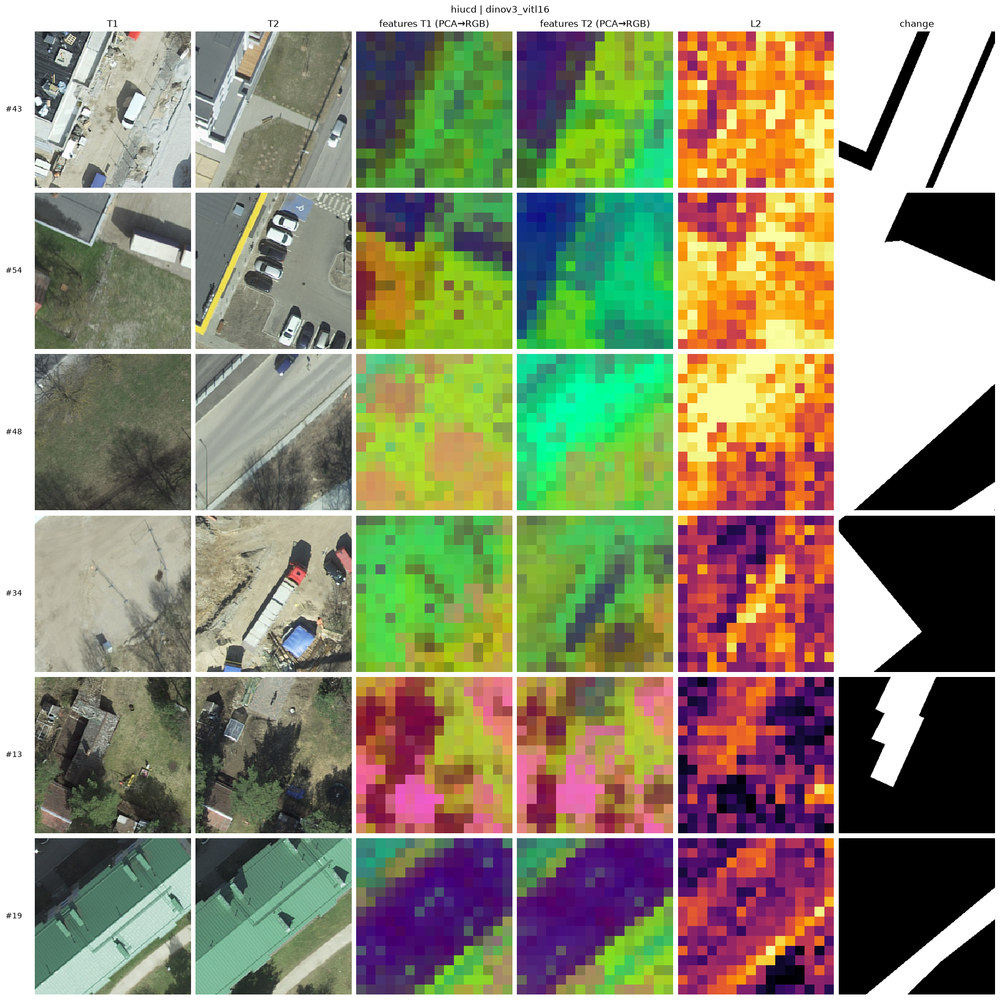

In [27]:
# cell 3: what the encoder "sees": PCA→RGB feature maps on the crops with the most change
changed_per_crop = va["change"].reshape(va["meta"]["n_samples"], -1).mean(1)
samples = np.argsort(changed_per_crop)[::-1][:6]      # 6 crops with the largest changed area
rgb_pca = V.fit_rgb_pca(va)                           # 3-component PCA on val T1 + T2 features, no labels
V.pca_rgb_figure(va, samples, rgb_pca, score=s_va["L2"], title=f"{DATA} | {ENC}")
plt.show()

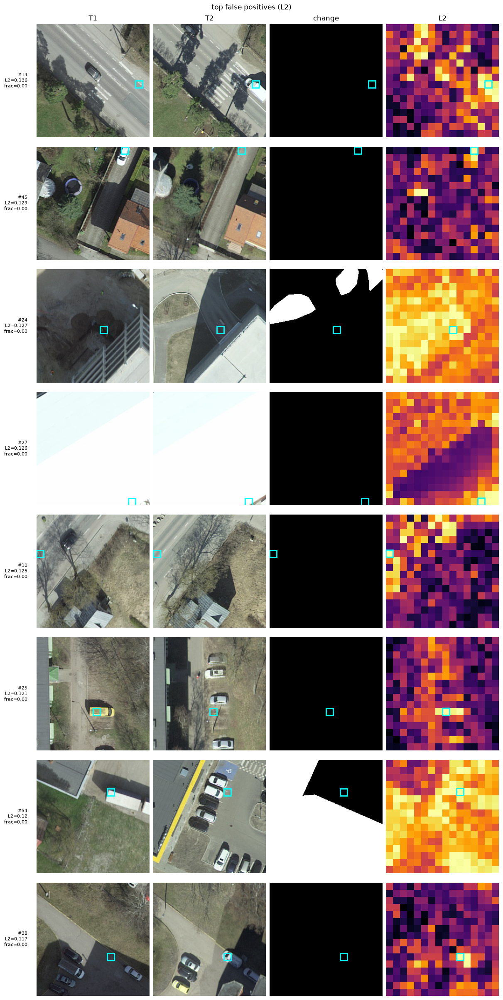

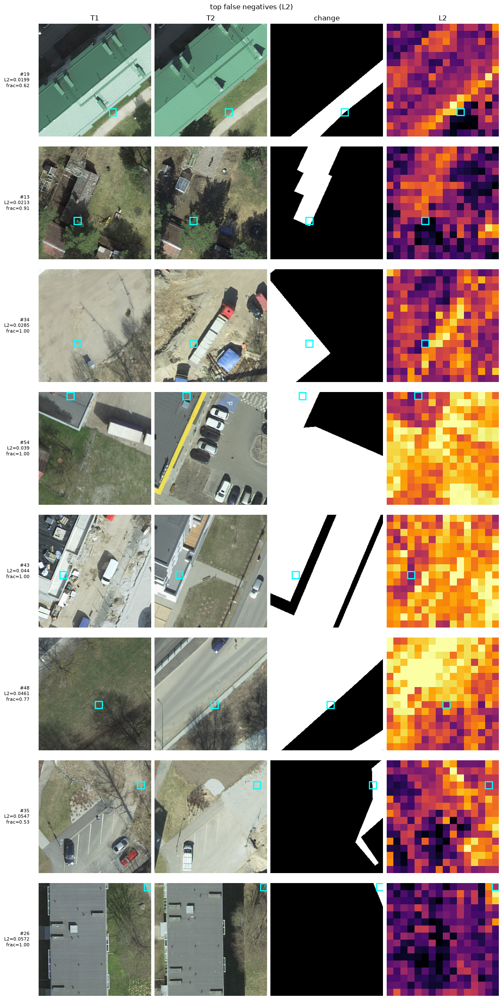

In [28]:
# cell 4: worst errors of a score
V.gallery_figure(va, s_va["L2"], kind="fp", n=8, score_name="L2"); plt.show()
V.gallery_figure(va, s_va["L2"], kind="fn", n=8, score_name="L2"); plt.show()

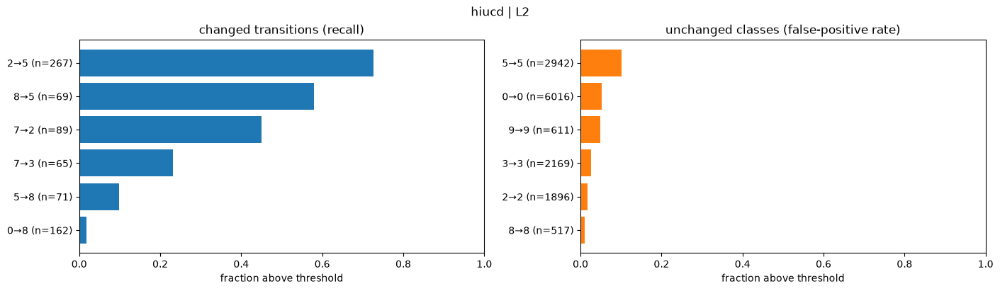

In [29]:
# cell 5 (Hi-UCD only): which land-cover transitions are detected / cause false positives
if va["meta"]["has_landcover"]:
    thr, _ = A.best_f1_threshold(A.l2_distance(tr["x"], tr["y"]), tr["label"])
    rows = A.per_transition(s_va["L2"], va["label"], va["lc1"], va["lc2"], thr)
    V.transition_figure(rows, f"{DATA} | L2"); plt.show()

741 false-positive patches at the threshold


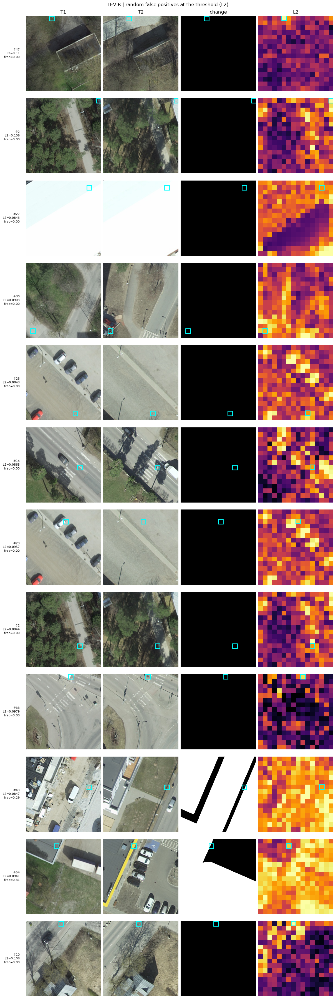

In [30]:
# random false positives at the train threshold (not only the most extreme)
thr = A.best_f1_threshold(A.l2_distance(tr["x"], tr["y"]), tr["label"])[0]
fp = np.where((va["label"] == 0) & (s_va["L2"] > thr))[0]
print(len(fp), "false-positive patches at the threshold")
pick = np.random.default_rng(0).choice(fp, 12, replace=False)
V.gallery_figure(va, s_va["L2"], picked=pick, score_name="L2",
                 title="LEVIR | random false positives at the threshold (L2)"); plt.show()

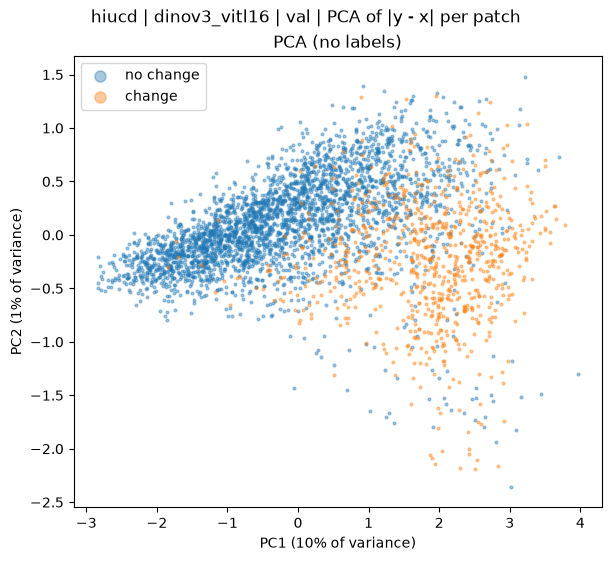

In [18]:
# PCA of the difference vectors |y - x| (no labels)
X_tr = A.abs_difference(tr["x"], tr["y"])      # |y - x| per patch, (N, C)
X_va = A.abs_difference(va["x"], va["y"])
fig, pca = V.pca_scatter_figure(X_tr, X_va, va["label"],
                                title=f"{DATA} | {ENC} | val | PCA of |y - x| per patch")
plt.show()
# fig.savefig(f"../results/{DATA}_{ENC}_pca_scatter.png", dpi=120)
del X_tr, X_va   # large arrays (N × 1024 for ViT-L)
# fig.savefig(f"../results/{DATA}_pca_scatter.png", dpi=120)

In [16]:
# norms and L2 vs cosine, for each encoder and dataset (val)
import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from pds_cd.features import load_features
from pds_cd import analysis as A

for data in ["hiucd", "levir"]:
    for enc in ["dinov2_vits14", "resnet50_l3"]:
        d = load_features(data, enc, "val", with_images=False)
        x, y, lab = d["x"].astype(np.float32), d["y"].astype(np.float32), d["label"]
        nx, ny = np.linalg.norm(x, axis=1), np.linalg.norm(y, axis=1)
        l2, cos = A.l2_distance(x, y), A.cosine_distance(x, y)
        print(f"{data:6s} {enc:14s} | norm CV {nx.std()/nx.mean():.3f}"
              f" | spearman(L2, cos) {spearmanr(l2, cos).correlation:.3f}"
              f" | AUROC |‖y‖-‖x‖| {roc_auc_score(lab, np.abs(ny - nx)):.3f}")
        del d, x, y

hiucd  dinov2_vits14  | norm CV 0.050 | spearman(L2, cos) 0.987 | AUROC |‖y‖-‖x‖| 0.595
hiucd  resnet50_l3    | norm CV 0.152 | spearman(L2, cos) 0.853 | AUROC |‖y‖-‖x‖| 0.593
levir  dinov2_vits14  | norm CV 0.041 | spearman(L2, cos) 0.992 | AUROC |‖y‖-‖x‖| 0.588
levir  resnet50_l3    | norm CV 0.145 | spearman(L2, cos) 0.857 | AUROC |‖y‖-‖x‖| 0.637


In [17]:
import torch
from pds_cd.model import build_encoder
enc = build_encoder({"encoder": "dinov3_vits16", "crop": 256}, "cuda")
f = enc(torch.rand(2, 3, 256, 256, device="cuda"))
print(f.shape)   # expected: torch.Size([2, 384, 16, 16])

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

torch.Size([2, 384, 16, 16])


In [ ]:
import torch
from pds_cd.model import build_encoder
for name in ["dinov3_vitl16", "dinov3_vitl16_sat"]:
    enc = build_encoder({"encoder": name, "crop": 256}, "cuda")
    print(name, enc(torch.rand(2, 3, 256, 256, device="cuda")).shape)   # expected: torch.Size([2, 1024, 16, 16])
    del enc; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/745 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

dinov3_vitl16 torch.Size([2, 1024, 16, 16])


config.json:   0%|          | 0.00/745 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

dinov3_vitl16_sat torch.Size([2, 1024, 16, 16])


In [ ]:
import torch
from pds_cd.model import build_encoder
enc = build_encoder({"encoder": "sam_vitb", "crop": 256}, "cuda")
print(enc(torch.rand(2, 3, 256, 256, device="cuda")).shape)   # expected: torch.Size([2, 256, 16, 16])

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

torch.Size([2, 256, 16, 16])
